In [1]:
# Imports necesarios para el análisis
import zipfile
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency, pearsonr, probplot
from IPython.display import display
sns.set(style="whitegrid")

In [2]:
# Load the dataset
df = pd.read_csv('amz_uk_price_prediction_dataset.csv')
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


## Part 1: Analyzing Best-Seller Trends Across Product Categories
 Objective: Understand the relationship between product categories and their best-seller status.
 1) Crosstab Analysis:
    - Create a crosstab between the product `category` and the `isBestSeller` status.
    - Are there categories where being a best-seller is more prevalent?
      Hint: calculate the proportion of best-sellers for each category and sort descending.
 2) Statistical Tests:
    - Conduct a Chi-square test to determine if the best-seller distribution is independent of the product category.
    - Compute Cramér's V to understand the strength of association between best-seller status and category.
 3) Visualizations:
    - Visualize the relationship using a stacked bar chart of `category` vs `isBestSeller`.

In [3]:
# Crear tabla cruzada
cross_tab = pd.crosstab(df['category'], df['isBestSeller'])
cross_tab


isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [4]:
proportions = (
    pd.crosstab(df['category'], df['isBestSeller'], normalize='index')
    .rename(columns={0: 'not_best_seller', 1: 'best_seller'})
)

proportions['best_seller_pct'] = proportions['best_seller'] * 100

# Ordenar y redondear a 2 decimales
proportions = proportions.sort_values(by='best_seller_pct', ascending=False)
proportions = proportions.round(2)

display(proportions)

isBestSeller,not_best_seller,best_seller,best_seller_pct
category,,,
Grocery,0.94,0.06,5.81
Smart Home Security & Lighting,0.94,0.06,5.77
Health & Personal Care,0.94,0.06,5.77
Mobile Phone Accessories,0.96,0.04,4.25
Power & Hand Tools,0.96,0.04,3.53
...,...,...,...
Bedding Collections,1.00,0.00,0.00
CPUs,1.00,0.00,0.00
"CD, Disc & Tape Players",1.00,0.00,0.00


Sí, las categorias "Grocery", "Smart home Security & Lighting" y "Health & Personal Care" la proporcion de best seller es mayor.

In [5]:
contingency_table = pd.crosstab(df['category'], df['isBestSeller'])
contingency_table

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [6]:
#test chi-cuadrado
chi2, p, dof, expected = chi2_contingency(contingency_table)
print("Chi-square statistic:", chi2)
print("Degrees of freedom:", dof)
print("p-value:", p)

Chi-square statistic: 36540.20270061387
Degrees of freedom: 295
p-value: 0.0


In [7]:
# V de Cramer
n = cross_tab.sum().sum()  # total de observaciones
phi2 = chi2 / n
r, k = cross_tab.shape
cramer_v = np.sqrt(phi2 / min(k-1, r-1))
print("V de Cramér:", cramer_v)


V de Cramér: 0.1222829439760564


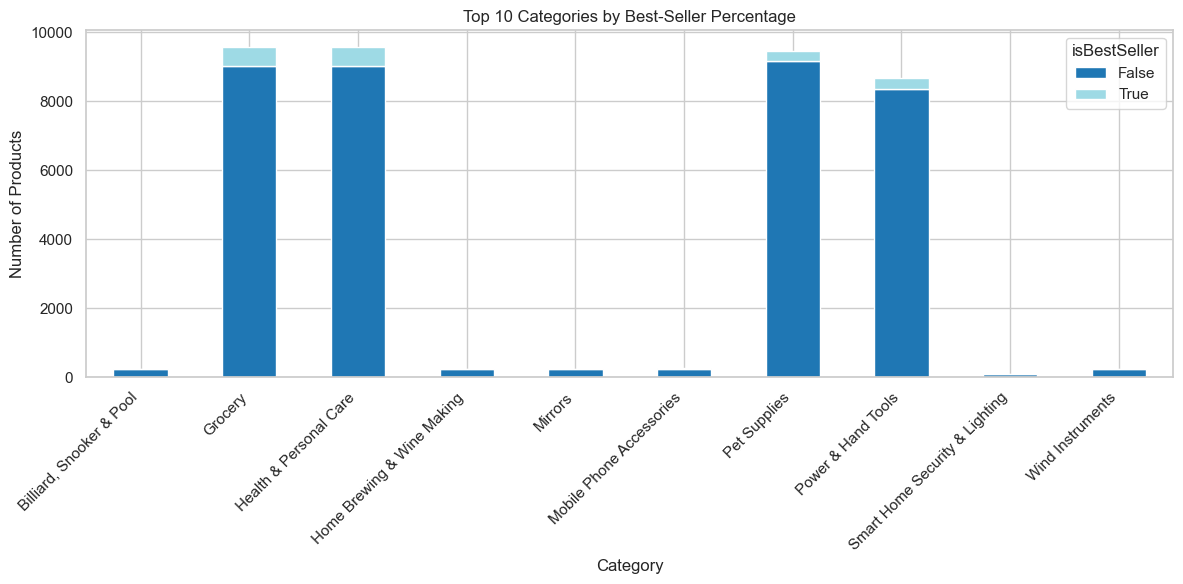

In [9]:
# Seleccionar las top 10 categorías con mayor % de best-sellers
top10 = proportions.sort_values('best_seller_pct', ascending=False).head(10)
top10
contingency_top10 = pd.crosstab(
    df[df['category'].isin(top10.index)]['category'],
    df['isBestSeller']
)
contingency_top10.plot(
    kind='bar',
    stacked=True,
    figsize=(12,6),
    colormap='tab20'
)
plt.title("Top 10 Categories by Best-Seller Percentage")
plt.xlabel("Category")
plt.ylabel("Number of Products")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

## Part 2: Exploring Product Prices and Ratings Across Categories and Brands
 Objective: Investigate how different product categories influence product prices.
 Preliminary Step: Remove outliers in product prices using the IQR method.
    - Products below Q1 - 1.5*IQR or above Q3 + 1.5*IQR are outliers.
 1) Violin Plots:
    - Visualize the distribution of `price` across product `categories`.
    - Filter out the top 20 categories based on count for better visualization.
    - Which category tends to have the highest median price? (No top filter here.)
 2) Bar Charts:
    - Compare the average price of products for the top 10 categories (by count).
    - Which category commands the highest average price? (No top filter here.)
 3) Box Plots:
    - Visualize the distribution of product `ratings` (`stars`) by `category` using side-by-side box plots.
    - Filter out the top 10 categories based on count for better visualization.
    - Which category tends to receive the highest median rating? (No top filter here.)

In [10]:
# Calcular Q1, Q3 e IQR
Q1 = df['price'].quantile(0.25)
Q3 = df['price'].quantile(0.75)
IQR = Q3 - Q1

# Límites inferior y superior
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filtrar outliers
df_no_outliers = df[(df['price'] >= lower_bound) & (df['price'] <= upper_bound)]

print("Tamaño original:", len(df))
print("Tamaño sin outliers:", len(df_no_outliers))


Tamaño original: 2443651
Tamaño sin outliers: 2115963


In [11]:
# Top 20 categorías más frecuentes
top20_categories = (
    df_no_outliers['category']
    .value_counts()
    .head(20)
    .index
)

df_top20 = df_no_outliers[df_no_outliers['category'].isin(top20_categories)]


In [12]:
df_no_outliers['category'].value_counts().head(20)


category
Sports & Outdoors                         694092
Beauty                                     19233
Bath & Body                                19050
Manicure & Pedicure Products               18904
Handmade Clothing, Shoes & Accessories     18811
Make-up                                    18718
Skin Care                                  18686
Hair Care                                  18625
Birthday Gifts                             18398
Handmade Gifts                             17948
Handmade Home Décor                        17675
Luggage and travel gear                    17557
Women                                      17476
Fragrances                                 17431
Handmade Kitchen & Dining                  17346
Handmade Artwork                           17269
Handmade Home & Kitchen Products           17175
Handmade Jewellery                         17135
Men                                        16596
Baby                                       14883
Name: count

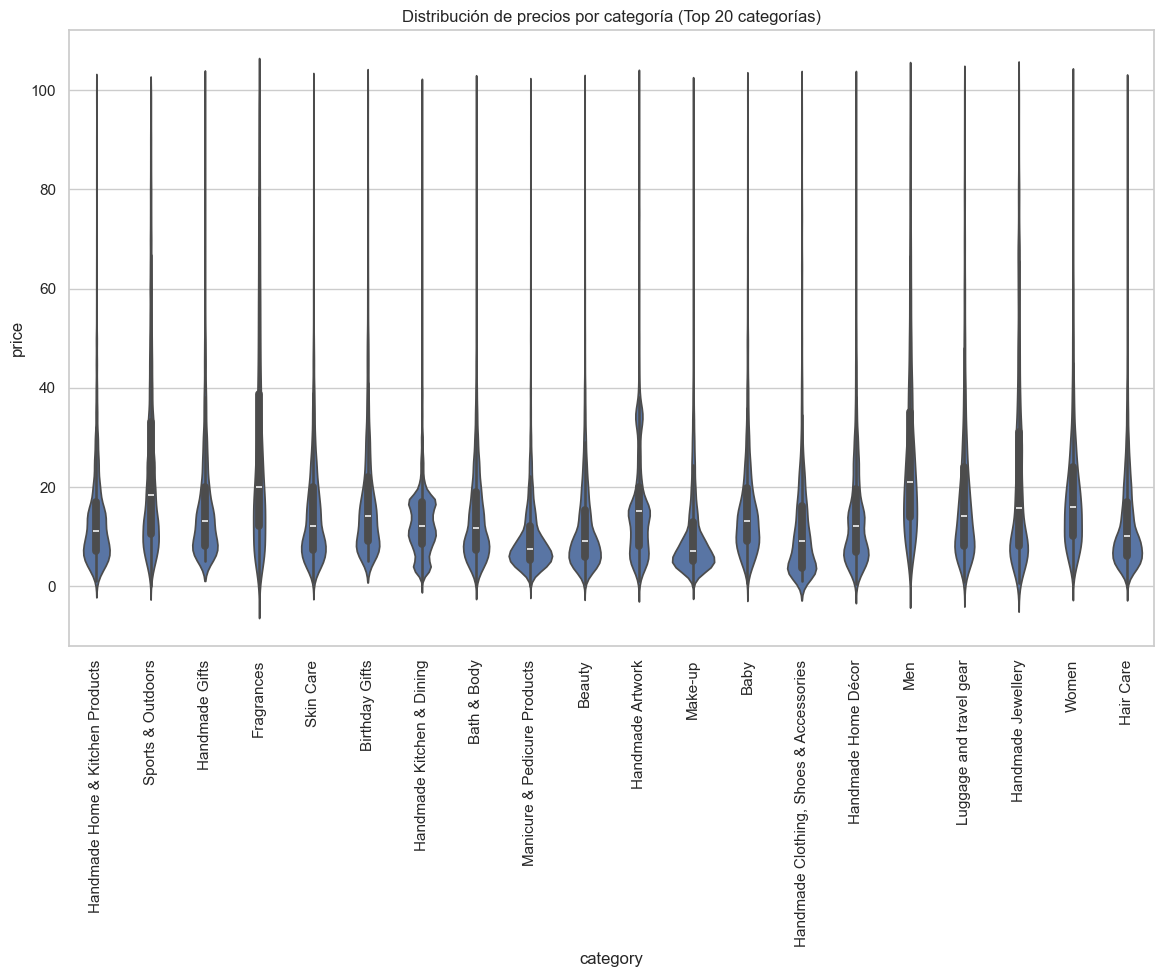

In [13]:
plt.figure(figsize=(14, 8))
sns.violinplot(
    data=df_top20,
    x='category',
    y='price'
)
plt.xticks(rotation=90)
plt.title("Distribución de precios por categoría (Top 20 categorías)")
plt.show()


Todas las categorias tienen precios muy dispersos, existencias de prductos premium, aunque la mayoria de productos se concentran entre 5 y 20 euros. Las categorias con precios mas altos son las que tienen el "violin" mas ancho "Handmade Home & Kitchen Products", "Handmade Artwork", "Handmade Gifts" y "Luggage and travel gear". Las categorias con precios mas bajos y concentrados son "Baby", "Women", "Men", "Handmade Jewellery" y "Skin Care / Beauty"

In [14]:
mean_prices = (
    df_no_outliers.groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)

display(mean_prices.head(10))  # Muestra las 10 categorías con media más alta


category
Motherboards         68.77
Boxing Shoes         67.42
Desktop PCs          66.92
Tablets              66.55
Graphics Cards       65.10
Digital Frames       60.75
Streaming Clients    60.24
Hockey Shoes         60.09
Computer Cases       58.34
Skiing Poles         57.87
Name: price, dtype: float64

Las categorias relacionadas con electronica u ordenadores suelen aparecer arriba porque incluyen productos mas caros.

In [15]:
# Obtener las 10 categorias principales por numero de productos 
top10_categories = df_no_outliers['category'].value_counts().head(10).index
print(top10_categories)


Index(['Sports & Outdoors', 'Beauty', 'Bath & Body',
       'Manicure & Pedicure Products',
       'Handmade Clothing, Shoes & Accessories', 'Make-up', 'Skin Care',
       'Hair Care', 'Birthday Gifts', 'Handmade Gifts'],
      dtype='object', name='category')


In [16]:
# Calcular precio promedio para estas 10 categorias
top10_mean_prices = (
    df_no_outliers[df_no_outliers['category'].isin(top10_categories)]
    .groupby('category')['price']
    .mean()
    .sort_values(ascending=False)
    .round(2)
)
print(top10_mean_prices)

category
Sports & Outdoors                         25.17
Birthday Gifts                            18.60
Handmade Gifts                            17.40
Skin Care                                 15.65
Bath & Body                               14.68
Hair Care                                 13.46
Handmade Clothing, Shoes & Accessories    12.96
Beauty                                    12.52
Make-up                                   10.61
Manicure & Pedicure Products              10.23
Name: price, dtype: float64


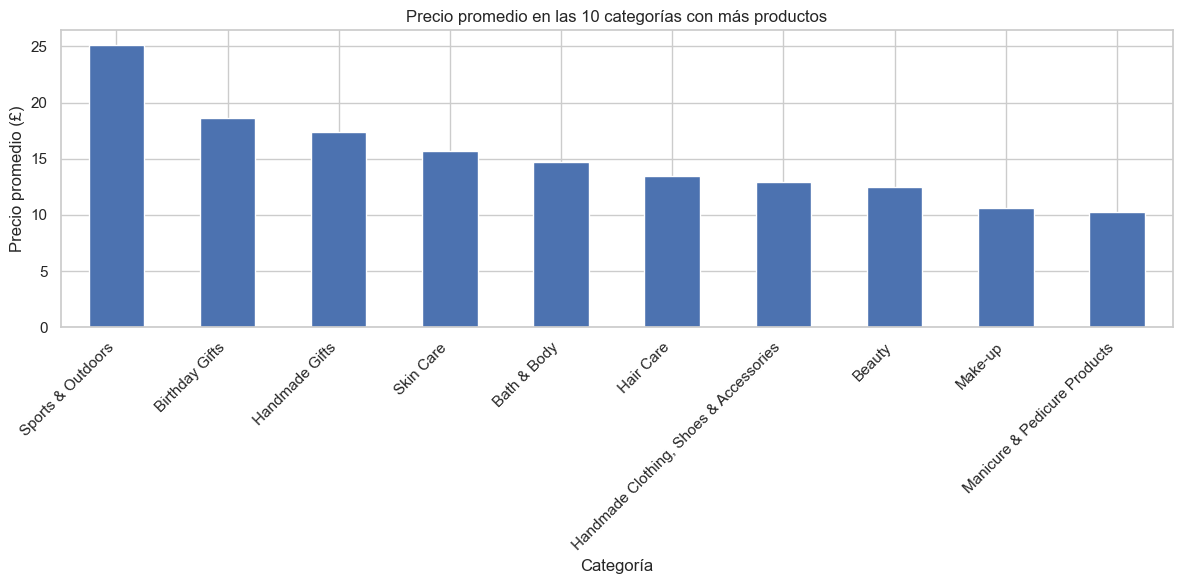

In [17]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12,6))
top10_mean_prices.plot(kind='bar')
plt.title("Precio promedio en las 10 categorías con más productos")
plt.xlabel("Categoría")
plt.ylabel("Precio promedio (£)")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()


In [19]:
# Categoria que tiene el precio promedio mas alto sin filtrar
median_prices = (
    df_no_outliers.groupby('category')['stars']
    .median()
    .sort_values(ascending=False)
    .round(2)
)

display(median_prices.head(10))


category
Computer Memory                 4.7
Beer, Wine & Spirits            4.6
Building & Construction Toys    4.6
Office Paper Products           4.6
Kids' Play Figures              4.6
Laptop Accessories              4.6
Hobbies                         4.6
Luxury Food & Drink             4.6
Soft Toys                       4.5
Boxes & Organisers              4.5
Name: stars, dtype: float64

In [20]:
# Top 10 categorías por número de productos
top10_categories = df['category'].value_counts().head(10).index

# Filtrar dataset para esas categorías
df_top10 = df[df['category'].isin(top10_categories)]
print(df_top10)


             uid        asin  \
82163      89483  B07DLGZ828   
82164      89484  B09HGZHXJT   
82165      89485  B08G2HBBB6   
82166      89486  B09D15SFMQ   
82167      89487  B08LD4VXGL   
...          ...         ...   
2429088  2806950  B0045I6SHW   
2429089  2806951  B0045I6NZY   
2429090  2806952  B003BLON3A   
2437153  2818782  B091HG57TP   
2437154  2818786  B09F8TFQDM   

                                                     title  stars  reviews  \
82163    Neutrade GoPro 3M Sticky Pads Double Sided Adh...    4.2     3116   
82164    WOLFANG Action Camera 4K 20MP GA100, Waterproo...    4.2     2594   
82165    GoPro HERO9 - Waterproof Sports Camera with Fr...    4.5     5161   
82166    GoPro HERO10 Black - Waterproof Action Camera ...    4.4     2467   
82167    FitStill 60M/196FT Waterproof Case for Go Pro ...    4.5     9879   
...                                                    ...    ...      ...   
2429088    Cannondale Men's Bibshort Dart Team Bike Shorts    0.0    

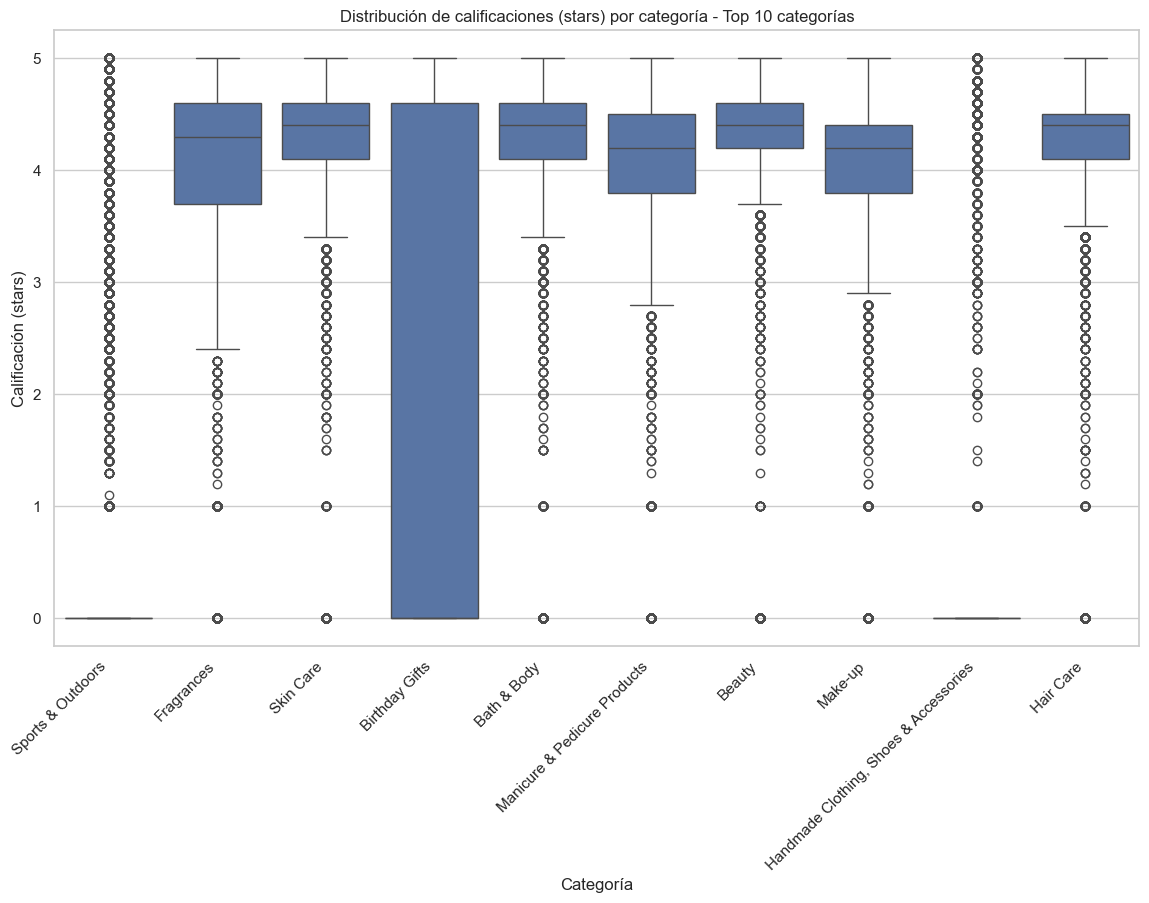

In [21]:
plt.figure(figsize=(14,8))
sns.boxplot(data=df_top10, x='category', y='stars')
plt.xticks(rotation=45, ha='right')
plt.title("Distribución de calificaciones (stars) por categoría - Top 10 categorías")
plt.ylabel("Calificación (stars)")
plt.xlabel("Categoría")
plt.show()


Todas las categorias tienen una mediana muy alta (4 y 4.5 estrellas). La categoria "Birthday Gifts" tiene muchas reviews con valor 0. "Skin Care" "Bath & Body" "Beauty" y "Hair Care" son categorías mas estables con opiniones similares. Las categorias "Sports & Outdoors" y "Handmade Clothing..." son mas dispersas, tienen mas outliers.

In [22]:
mean_ratings = df.groupby('category')['stars'].mean().sort_values(ascending=False).round(2)
display(mean_ratings.head(10))


category
Luxury Food & Drink                    4.55
Grocery                                4.47
Laptop Accessories                     4.45
Health & Personal Care                 4.44
Arts & Crafts                          4.43
Office Paper Products                  4.43
Customers' Most Loved                  4.41
Water Coolers, Filters & Cartridges    4.36
USB Hubs                               4.36
Cables & Accessories                   4.34
Name: stars, dtype: float64

## Part 3: Investigating the Interplay Between Product Prices and Ratings
 Objective: Analyze how product ratings (`stars`) correlate with product prices.
 1) Correlation Coefficients:
    - Calculate the correlation coefficient between `price` and `stars`.
    - Is there a significant correlation between product price and its rating?
 2) Visualizations:
    - Scatter plot: `stars` vs `price` to observe patterns.
    - Correlation heatmap: visualize correlations among numerical variables.
    - QQ plot: examine if product prices follow a normal distribution.

In [23]:
# Correlación entre price y stars
correlation = df_no_outliers['price'].corr(df_no_outliers['stars'])
print("Coeficiente de correlación (price vs stars):", round(correlation, 3))

Coeficiente de correlación (price vs stars): -0.078


El coeficiente de correlacion negativo pero muy cercano a 0, lo que significa que no hay relacion entreel precio y las calificaciones. Productos mas caros no necesariamente reciben mejores calificaciones y viceversa.

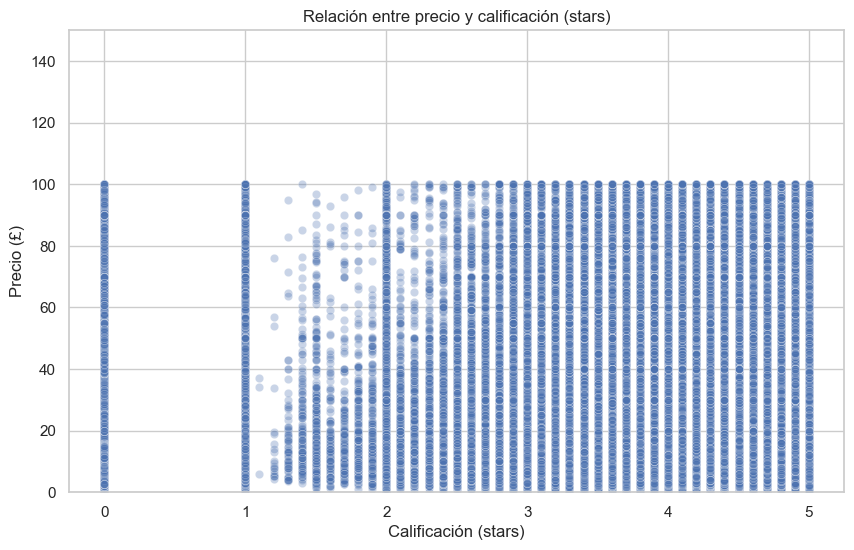

In [24]:
plt.figure(figsize=(10,6))
sns.scatterplot(data=df_no_outliers, x='stars', y='price', alpha=0.3)
plt.title("Relación entre precio y calificación (stars)")
plt.xlabel("Calificación (stars)")
plt.ylabel("Precio (£)")
plt.ylim(0, 150)  # Limitar el eje Y para mejor visualización
plt.show()


No parece existir una correlación clara entre precio y calificacion. En todas las calificaciones hay productos baratos y caros. Esto sugiera que el precio no influye directamente en la valoración.

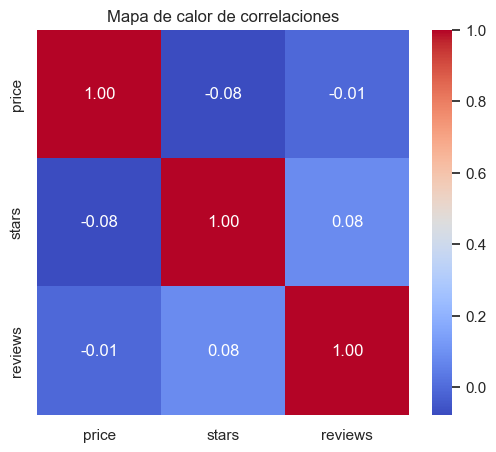

In [25]:
numeric_cols = ['price', 'stars', 'reviews']  # Puedes agregar otras columnas numéricas
corr_matrix = df_no_outliers[numeric_cols].corr()

plt.figure(figsize=(6,5))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f")
plt.title("Mapa de calor de correlaciones")
plt.show()


Prices vs stars --> -0.08 correlacion negativa muy debil (el precio no influye en la calificacion). Price vs reviuws --> -0.01 correlacion casi nula (el numero de reseñas no depende del precio). Stars vs reviews --> 0.08 correlacion positiva muy debil (los productos con mas reseñas tiendes ligeramente a tener mejores opiniones, pero al ser tan debil la correlacion no es determinante).

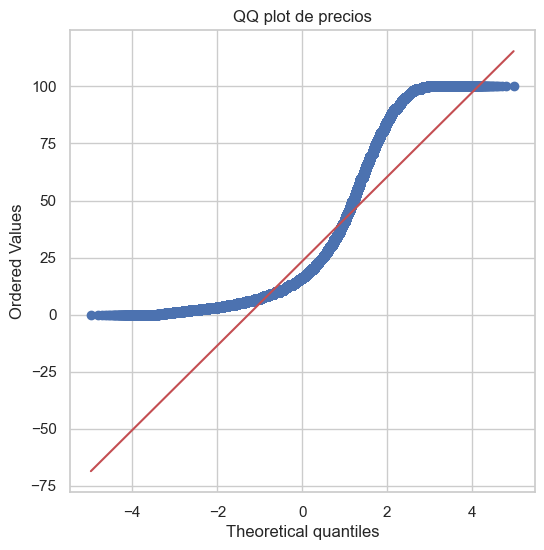

In [26]:
import scipy.stats as stats

plt.figure(figsize=(6,6))
stats.probplot(df_no_outliers['price'], dist="norm", plot=plt)
plt.title("QQ plot de precios")
plt.show()


Los puntos no siguen la linea recta, porque lo que los precios no siguen una distribucion normal. Curvatura en forma de "S", parte de la izquierda,muchos productos con precios muy bajos, en la parte central, los puntos se separan de la linea central. Parte derecha la cola larga, causada por productos caros (outliers).

# Bonus

In [29]:
# Correlación price vs stars sin filtrar outliers
correlation_all = df['price'].corr(df['stars'])
print("Coeficiente de correlación (price vs stars) sin eliminar outliers:", round(correlation_all, 3))

Coeficiente de correlación (price vs stars) sin eliminar outliers: -0.125


El valor sigue siendo negativo y cercano a 0, indicando una correlacion debil. Comparandolo con la correlacion (eliminando outliers), se hizo ligeramente más negativa.

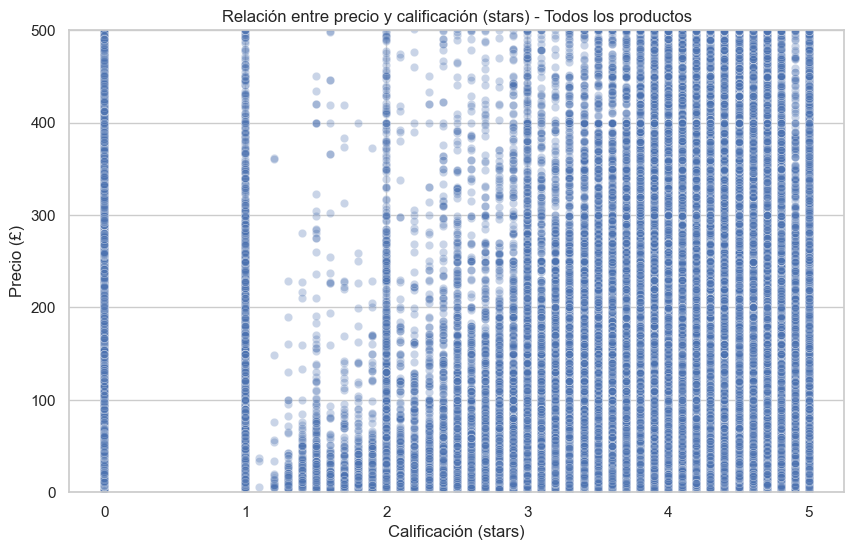

In [27]:
# Scatter plot sin eliminar outliers
plt.figure(figsize=(10,6))
sns.scatterplot(data=df, x='stars', y='price', alpha=0.3)
plt.title("Relación entre precio y calificación (stars) - Todos los productos")
plt.xlabel("Calificación (stars)")
plt.ylabel("Precio (£)")
plt.ylim(0, 500)  # Puedes limitar el eje Y para mejor visualización
plt.show()


El diagrama de dispersión no muestra una relación clara entre el precio de los productos y sus calificaciones. Para todos los niveles de calificación existen productos con precios bajos y altos, lo que confirma la ausencia de una correlación significativa entre ambas variables.

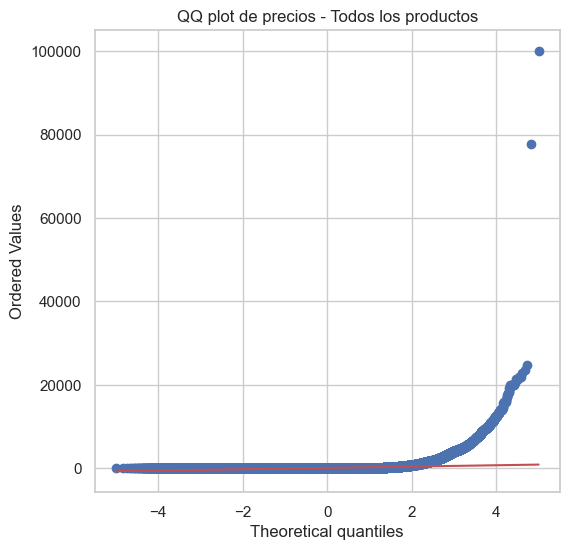

In [28]:
# QQ plot de precios sin eliminar outliers
import scipy.stats as stats
plt.figure(figsize=(6,6))
stats.probplot(df['price'], dist="norm", plot=plt)
plt.title("QQ plot de precios - Todos los productos")
plt.show()


El QQ plot revela una distribución de precios fuertemente sesgada a la derecha, con colas pesadas y valores atípicos extremos, lo que indica que los precios se desvían claramente de la normalidad y están dominados por un pequeño número de productos con precios muy elevados.